# Checking declared crops with Sentinel-2-like time series

Farmers declare a crop for each parcel. An area-monitoring system checks those declarations against satellite observations
and flags the parcels that do not fit (Commission Implementing Regulation (EU) 2022/1173).

This tutorial runs the whole check offline on a synthetic scene where **the true crop of every parcel is known**,
and 6 % of the declarations are deliberately wrong. That lets you see what the method catches and why.

You will:

1. build the scene as a labelled `xarray` Dataset;
2. load and validate a configuration;
3. run the check and read the out-of-fold accuracy;
4. look inside: parcel states, mowing events and threshold calibration;
5. read the traffic-light verdicts, with their reasons;
6. save a reproducible run;
7. run the same check chunk by chunk and get identical verdicts.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from parcelmon import config, pipeline, states, synthetic

plt.rcParams.update({"figure.dpi": 90})

## 1. The scene

144 parcels of 8 × 8 pixels (10 m), four crop groups with different phenologies, a Sentinel-2-like revisit of 5 days
from March to October, and clouds over part of the scene on about 30 % of the dates.

In [2]:
scene = synthetic.make_scene(n_side=12, seed=7, mislabel_rate=0.06)
ds = synthetic.to_dataset(scene)
parcels = scene["parcels"].set_index("parcel_id")
print(ds)
print("\nwrong declarations:", int((parcels.true_group != parcels.declared_group).sum()), "of", len(parcels))

<xarray.Dataset> Size: 5MB
Dimensions:  (time: 49, y: 109, x: 109)
Coordinates:
  * time     (time) datetime64[us] 392B 2025-03-01 2025-03-06 ... 2025-10-27
  * y        (y) float64 872B 1.085e+03 1.075e+03 1.065e+03 ... 25.0 15.0 5.0
  * x        (x) float64 872B 5.0 15.0 25.0 ... 1.065e+03 1.075e+03 1.085e+03
Data variables:
    ndvi     (time, y, x) float64 5MB 0.1 0.1 0.1 0.1 0.1 ... 0.1 0.1 0.1 0.1
    clear    (time, y, x) bool 582kB True True True True ... True True True True
    labels   (y, x) int32 48kB 0 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
Attributes:
    description:  synthetic parcels and NDVI-like series (parcelmon.synthetic)

wrong declarations: 13 of 144


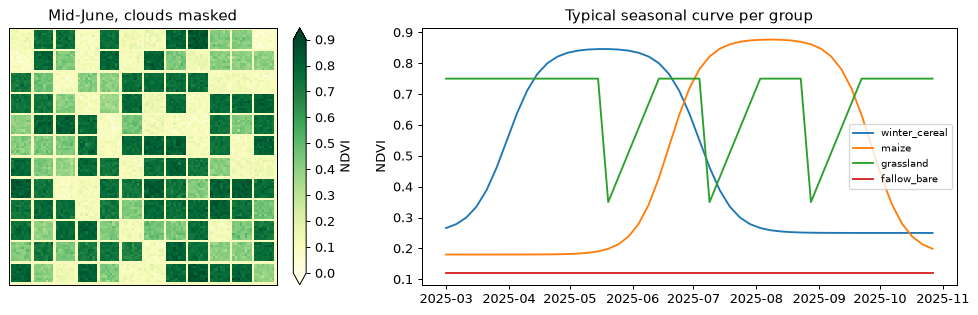

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
june = ds.sel(time="2025-06-15", method="nearest")
june["ndvi"].where(june["clear"]).plot.imshow(ax=ax[0], cmap="YlGn", vmin=0, vmax=0.9, cbar_kwargs={"label": "NDVI"})
ax[0].set_title("Mid-June, clouds masked")
ax[0].set_xticks([])
ax[0].set_yticks([])
ax[0].set_xlabel("")
ax[0].set_ylabel("")
doy = ds.time.dt.dayofyear.values.astype(float)
for group, curve in synthetic.PHENOLOGY.items():
    ax[1].plot(ds.time.values, curve(doy), label=group)
ax[1].set_ylabel("NDVI")
ax[1].set_title("Typical seasonal curve per group")
ax[1].legend(fontsize=8)
plt.tight_layout()

## 2. Configuration

Every threshold that changes the result is stated in a YAML file; there are no hidden defaults.
The file is validated on loading. Wrong types, out-of-range values and contradictions are all reported at once.

In [4]:
cfg = config.load_config(Path("..") / "tests" / "synthetic_config.yaml")
print("states:", cfg.states)
print("verdict:", cfg.verdict)

broken = config.Config(**{**{k: getattr(cfg, k) for k in ("parcels", "crop_groups", "preprocessing", "timeseries",
                                                          "events", "classifier", "states")},
                          "verdict": {"p_high": 0.4, "p_low": 0.6}})
try:
    broken.validate()
except ValueError as err:
    print("\n" + str(err))

states: {'bare_max': 0.25, 'vegetated_min': 0.5, 'bare_season_fraction': 0.8}
verdict: {'p_high': 0.7, 'p_low': 0.3, 'downgrade_rules': {'maize': ['bare_all_season', 'no_vegetation_peak']}}

invalid config:
- verdict thresholds must satisfy 0 <= p_low < p_high <= 1


## 3. Run the check

`run_dataset` takes the Dataset directly. The index layers, the parcel raster and the cloud mask must be on exactly the same grid;
a shifted raster raises an error instead of being matched to the wrong parcels.

The classifier is a Random Forest, but every parcel's probabilities come from a model that **did not see that parcel or its spatial block**
(out-of-fold, spatial-block cross-validation). Otherwise agreement would be over-estimated (Roberts et al. 2017).

In [5]:
res = pipeline.run_dataset(cfg, ds, parcels, labels="labels", clear="clear")
res.summary()

{'n_parcels': 144,
 'verdicts': {'agree': 123, 'disagree': 13, 'inconclusive': 8},
 'overall_accuracy': 0.9097222222222222,
 'macro_f1': 0.9086818946580242}

In [6]:
res.report["confusion"]

predicted,fallow_bare,grassland,maize,winter_cereal
reference,,,,
fallow_bare,30,1,3,0
grassland,2,38,0,1
maize,2,1,31,0
winter_cereal,1,0,2,32


The accuracy is measured **against the declarations**, which contain errors on purpose here. Agreement can therefore never reach 1,
and the off-diagonal cells include the wrong declarations themselves. That is exactly what the check is meant to find.

## 4. Inside the method

### Parcel states and events

Each parcel's series is cleaned, put on a regular 10-day grid (gaps longer than `max_gap_days` are not bridged), and smoothed.
Each date is then labelled bare, low cover or vegetated with two NDVI thresholds. A drop of at least `min_drop` within
`max_drop_days` after a peak is an event: repeated drops are typical of mowing.

,frac_bare,frac_vegetated,n_drop_events,rule_reasons
parcel_id,,,,
8,0.25,0.416667,0,[no_drop_event]
10,0.44,0.440000,2,[]
2,0.00,0.750000,3,[]
1,1.00,0.000000,0,"[bare_all_season, no_vegetation_peak, no_drop_..."


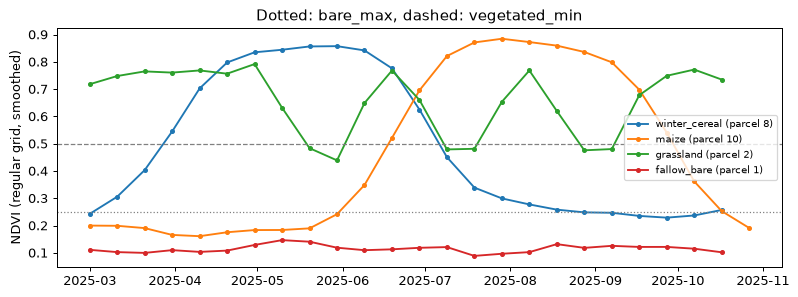

In [7]:
example = {g: parcels.index[(parcels.true_group == g) & (parcels.declared_group == g)][0] for g in synthetic.PHENOLOGY}
series = res.series["ndvi"]
fig, ax = plt.subplots(figsize=(9, 3.4))
for group, pid in example.items():
    ax.plot(series.columns, series.loc[pid], marker=".", label=f"{group} (parcel {pid})")
ax.axhline(cfg.states["bare_max"], color="grey", ls=":", lw=1)
ax.axhline(cfg.states["vegetated_min"], color="grey", ls="--", lw=1)
ax.set_ylabel("NDVI (regular grid, smoothed)")
ax.legend(fontsize=8)
ax.set_title("Dotted: bare_max, dashed: vegetated_min")
plt.tight_layout()

res.rules.loc[list(example.values()), ["frac_bare", "frac_vegetated", "n_drop_events", "rule_reasons"]]

### Calibrating a threshold instead of guessing it

The example thresholds (0.25 / 0.5) are choices, and real values depend on region and sensor.
With reference observations, `youden_threshold` picks the value that best separates two classes (maximum Youden's J).
Here the reference is the known bare fallow parcels against everything else, in mid-season.

In [8]:
mid = series.loc[:, "2025-06-01":"2025-08-31"]
is_bare = parcels.loc[mid.index, "true_group"].eq("fallow_bare").to_numpy()
threshold, j = states.youden_threshold(negative=mid[is_bare].to_numpy().ravel(),
                                       positive=mid[~is_bare].to_numpy().ravel())
print(f"calibrated bare/vegetated split: NDVI {threshold:.3f} (Youden J = {j:.2f})")
print(f"the config uses bare_max = {cfg.states['bare_max']}")

calibrated bare/vegetated split: NDVI 0.212 (Youden J = 1.00)
the config uses bare_max = 0.25


## 5. Verdicts

| Verdict | Meaning |
|---|---|
| `agree` | the declared group is probable (≥ `p_high`) and no rule conflicts |
| `disagree` | the declared group is improbable (≤ `p_low`) and another group is probable |
| `inconclusive` | anything else, or the parcel cannot be judged (too small, too few clear dates) |

Here we can compare the verdicts with the truth.

In [9]:
v = res.verdicts.join(parcels[["true_group"]])
v["declaration_correct"] = v["declared_group"] == v["true_group"]
pd.crosstab(v["declaration_correct"], v["verdict"], margins=True)

verdict,agree,disagree,inconclusive,All
declaration_correct,,,,
False,0,13,0,13
True,123,0,8,131
All,123,13,8,144


In [10]:
v.loc[~v["declaration_correct"], ["declared_group", "true_group", "verdict", "reasons"]].head(8)

,declared_group,true_group,verdict,reasons
parcel_id,,,,
19,grassland,winter_cereal,disagree,[no_drop_event]
25,fallow_bare,grassland,disagree,[]
27,maize,fallow_bare,disagree,"[bare_all_season, no_vegetation_peak, no_drop_..."
43,grassland,fallow_bare,disagree,"[bare_all_season, no_vegetation_peak, no_drop_..."
49,winter_cereal,maize,disagree,[]
88,winter_cereal,fallow_bare,disagree,"[bare_all_season, no_vegetation_peak, no_drop_..."
114,grassland,fallow_bare,disagree,"[bare_all_season, no_vegetation_peak, no_drop_..."
115,fallow_bare,maize,disagree,[]


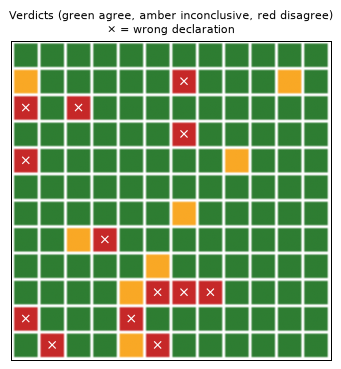

In [11]:
colours = {"agree": 0, "inconclusive": 1, "disagree": 2}
lab = ds["labels"].values
verdict_map = np.full(lab.shape, np.nan)
for pid, row in v.iterrows():
    verdict_map[lab == pid] = colours[row["verdict"]]
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(verdict_map, cmap=plt.matplotlib.colors.ListedColormap(["#2e7d32", "#f9a825", "#c62828"]), vmin=0, vmax=2)
wrong = v.index[~v["declaration_correct"]]
for pid in wrong:
    r, c = np.argwhere(lab == pid).mean(axis=0)
    ax.text(c, r, "×", ha="center", va="center", fontsize=11, color="white")
ax.set_title("Verdicts (green agree, amber inconclusive, red disagree)\n× = wrong declaration", fontsize=9)
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()

## 6. Save a reproducible run

`save` writes every table, **the configuration actually used**, and a short summary.
The saved `config.yaml` loads back as a valid, identical configuration, so anyone can repeat the run.

In [12]:
with tempfile.TemporaryDirectory() as tmp:
    out = res.save(Path(tmp) / "run")
    print(sorted(p.name for p in out.iterdir()))
    print("config round-trip identical:", config.load_config(out / "config.yaml") == cfg)

['accuracy_per_class.csv', 'config.yaml', 'confusion.csv', 'folds.csv', 'observations.csv', 'proba.csv', 'rules.csv', 'series_ndvi.csv', 'states.csv', 'summary.json', 'verdicts.csv']
config round-trip identical: True


## 7. Larger areas: chunk by chunk, same answer

With dask-backed data, parcel statistics are computed one chunk at a time. Parcels that cross chunk borders
are handled exactly, so the verdicts are identical. For memory and time figures, see the README's Scaling section.

In [13]:
chunked = ds.chunk({"time": 10, "y": 40, "x": 40})
res_chunked = pipeline.run_dataset(cfg, chunked, parcels, labels="labels", clear="clear")
print("identical verdicts:", res_chunked.verdicts.equals(res.verdicts))

identical verdicts: True


## With real data

`examples/demo_brp_sentinel2.py` runs the same check on Dutch BRP parcels (PDOK, public domain) and Sentinel-2 L2A from
Microsoft Planetary Computer, using `configs/brp_example.yaml`. It needs network access, but no account.

**References:** Sitokonstantinou et al. (2018); Inglada et al. (2015); Breiman (2001); Roberts et al. (2017);
Youden (1950); Olofsson et al. (2014); Defourny et al. (2019); Regulation (EU) 2022/1173.
The full list with DOIs is in the [README](../README.md#references).